# CVAE-GAN with different loss weights $\tau$

**The problem: the CVAE-GAN learns the average frame.** The CVAE-GAN and its loss are taken from [14] (see
`sport_vae.ipynb`). The loss fixes only $\tau_1 + \tau_2 + \tau_3 = 1$, so the weights have to be chosen for the data.
With equal weights, $\tau_1 = \tau_2 = \tau_3 = \tfrac13$, the trained encoder gives every latent slot
$\mu_{z,k} \approx 0$ and $\sigma_{z,k} \approx 1$, whatever frame it receives. The latent vector $z_k$ is then random
noise with no information about the frame, and the decoder can only redraw the average frame: its reconstruction
error is the same as always answering the mean frame.

**Why it happens.** Line 1 of the loss (the KL divergence) charges for every bit of information $z_k$ carries; line 2
rewards information only by the reconstruction error it removes. Lines 1 and 2 together are the loss of a standard
VAE that assumes Gaussian noise of variance $\sigma_x^2 = \tau_1/\tau_2$ on every tile. With equal weights that is noise
of about ±1, while the predicted crowd frames differ from their average by only a few hundredths per tile. To the loss,
these differences look like noise, and carrying no information at all is the cheapest solution. Equal weights
therefore cannot be used on these frames as they are.


**The test performed here.** The loss weights are changed so that information becomes cheaper: $\tau_1$ (the weight of
the KL charge) is lowered step by step, always with $\tau_1 + \tau_2 + \tau_3 = 1$. The data, the networks and the
training stay as in `sport_vae.ipynb`, so any change in the result comes from $\tau$ alone. Every setting is trained
several times on several splits of the viewers (section 1), and the weights are chosen on validation data and then
scored on test data that the choice never saw. The result is one table with four columns: $\tau_1$, $\tau_2$, $\tau_3$
and the RMSE.

## 0. Code

All the code used by this notebook is in the cells of this section; the experiment itself starts in section 1.

### Settings and paths

Every result is saved in `results/`; when the notebook is run again it loads the saved results instead of training
again, unless `RERUN = True`.

In [1]:
import os, time, random
from types import SimpleNamespace
from joblib import Parallel, delayed     # parallel runs that work on Linux, macOS and Windows

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# Paths are relative to this notebook's folder (run it with vae/sport/ as the working directory):
#   ../../dataset/360dataset/sensory/tile/          input:  one tile CSV per viewer
#   ../../predictor/sport/predictor_weights_sport.pt input:  the settings of the trained FoV predictor
#   ./figures/, ./results/                       output: figures and results tables
DATA_ROOT      = os.path.join("..", "..", "dataset", "360dataset")
PREDICTOR_FILE = os.path.join("..", "..", "predictor", "sport", "predictor_weights_sport.pt")
FIG_DIR, RES_DIR = "figures", "results"
assert os.path.exists(PREDICTOR_FILE), f"{PREDICTOR_FILE} not found; run ../../predictor/sport/fov_predictor_sport.ipynb first"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

DEVICE = torch.device("cpu")
torch.set_num_threads(1)
N_WORKERS = max(1, min(6, (os.cpu_count() or 2) - 1))
RERUN = False                            # False: load saved results if they exist; True: train every run again

BLUE, ORANGE, GREEN, GREY = "#1f5fbf", "#d9480f", "#2b8a3e", "#7a7a7a"
pd.set_option("display.width", 200)

### Data and viewer folds

Each viewer's tile CSV becomes 12 FoV maps, one every 5 s (10 × 20 tiles, 1 = tile in view). The 50 viewers are split
into 5 folds of 10: viewer number $i$ goes to fold $i \bmod 5$. `split(f)` gives the roles of the folds in turn $f$
(section 1).

In [2]:
ck  = torch.load(PREDICTOR_FILE, map_location=DEVICE)
cfg = ck["cfg"]                                                # the predictor's settings (video, grid, order n, ...)
H, W, N = cfg["H"], cfg["W"], cfg["n"]
N_SAMPLES   = cfg["video_seconds"] // cfg["sample_every_s"]    # 12 FoV maps per viewer, one every 5 s
KS          = list(range(N + 1, N_SAMPLES + 1))                # the 7 predicted time steps k = 6..12
CROWD       = cfg["users_per_epoch"]                           # 10 viewers per crowd
PRED_EPOCHS = -(-int(cfg["video_hours"] * 3600) // (CROWD * (N_SAMPLES - N) * cfg["sample_every_s"]))   # 494
VAE_EPOCHS  = 2 * PRED_EPOCHS                                  # 988
U = ck["U"]                                                    # the 50 viewers


def parse_tile_csv(path):
    # ragged 'frame, tile, tile, ...' CSV  ->  (n_frames, H, W) array of 0/1
    occ = []
    with open(path) as f:
        f.readline()
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            if not parts or parts[0] == "":
                continue
            g = np.zeros((H, W), np.float32)
            for x in (int(p) for p in parts[1:] if p != ""):
                j, i = divmod(x, W)
                if 0 <= j < H and 0 <= i < W:
                    g[j, i] = 1.0
            occ.append(g)
    return np.stack(occ)


step = cfg["sample_every_s"] * cfg["fps"]
G = {}                                                         # G[u]: the 12 FoV maps of viewer u, (12, H, W)
for u in U:
    occ = parse_tile_csv(os.path.join(DATA_ROOT, "sensory", "tile", cfg['folder'], f"{cfg['prefix']}_{u}_tile.csv"))
    G[u] = occ[[min(k * step, len(occ)) - 1 for k in range(1, N_SAMPLES + 1)]]

# the 5 viewer folds: viewer number i goes to fold (i - 1) mod 5, so every fold holds 10 viewers spread over the list
FOLDS = [[u for i, u in enumerate(U) if i % 5 == f] for f in range(5)]


def split(f):
    # outer fold f: test = fold f; validation = fold f+1; inner training = the other 3 folds (30 viewers);
    # outer training = everything except the test fold (40 viewers)
    test, val = FOLDS[f], FOLDS[(f + 1) % 5]
    inner = [u for g in range(5) if g not in (f, (f + 1) % 5) for u in FOLDS[g]]
    outer = [u for g in range(5) if g != f for u in FOLDS[g]]
    return SimpleNamespace(test=test, val=val, inner_train=inner, outer_train=outer)

### The FoV predictor, trained per fold

`train_predictor(users)` trains the FoV predictor network of `../../predictor/sport/fov_predictor_sport.ipynb` on the given
viewers only. It uses the predictor's first training procedure: 494 plain gradient-descent steps on the squared
error, each on a random group of 10 viewers. The saved predictor of that notebook was later retrained with Adam on
binary cross-entropy (`../../predictor/fov_videos_summary.md`); the fold predictors here keep the first procedure.
Only the final model (section 7 of `sport_vae_normalised_and_diff_weights.ipynb`) uses the saved predictor. `crowd_frames` averages the FoV maps of a group of viewers into crowd frames
and turns each window of 5 into a predicted frame $\hat F_k$, $k = 6, \dots, 12$: the input $X$ of the CVAE-GAN.
`training_frames` draws a new random group of 10 training viewers for each of the 988 epochs.

In [3]:
class CircularPad(nn.Module):
    # wrap columns (longitude, the 360-degree seam), zero-pad rows (latitude). x is (batch, C, H, W)
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, base_rate, n=5, width=16):
        super().__init__()
        self.pad1, self.conv1 = CircularPad(1), nn.Conv2d(n, width, 3)
        self.pad2, self.conv2 = CircularPad(2), nn.Conv2d(width, width, 3, dilation=2)
        self.head = nn.Conv2d(width, 1, 1)
        for conv in (self.conv1, self.conv2, self.head):
            nn.init.xavier_uniform_(conv.weight); nn.init.zeros_(conv.bias)
        nn.init.constant_(self.head.bias, float(np.log(base_rate / (1 - base_rate))))

    def forward(self, x):                                       # x: (batch, H, W, n), oldest map first
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # (batch, H, W)


def train_predictor(users):
    """The FoV predictor of ../../predictor/sport/fov_predictor_sport.ipynb, trained on `users` only, with its first procedure (494 plain gradient-descent steps)."""
    torch.set_num_threads(1)
    X = np.stack([np.stack([np.moveaxis(G[u][k - 1 - N:k - 1], 0, -1) for k in KS]) for u in users]).astype(np.float32)
    Y = np.stack([np.stack([G[u][k - 1] for k in KS]) for u in users]).astype(np.float32)
    X_t, Y_t = torch.from_numpy(X), torch.from_numpy(Y)        # (users, 7, H, W, n) and (users, 7, H, W)
    random.seed(cfg["seed"]); np.random.seed(cfg["seed"]); torch.manual_seed(cfg["seed"])
    model = Order5Predictor(float(Y.mean()), N, cfg["width"])
    rng, used, groups = np.random.default_rng(cfg["seed"]), set(), []
    while len(groups) < PRED_EPOCHS:                           # one distinct group of 10 viewers per epoch
        s = tuple(sorted(rng.choice(len(users), CROWD, replace=False).tolist()))
        if s not in used:
            used.add(s); groups.append(s)
    for e, s in enumerate(groups, start=1):
        idx = torch.tensor(s)
        Xb, Yb = X_t[idx].reshape(-1, H, W, N), Y_t[idx].reshape(-1, H, W)
        loss = torch.mean(torch.sum(torch.square(model(Xb) - Yb), dim=(1, 2)))
        grads = torch.autograd.grad(loss, list(model.parameters()))
        with torch.no_grad():
            for v, g in zip(model.parameters(), grads):
                v.sub_(cfg["lr_a"] / (cfg["lr_b"] + e) * g)     # plain gradient descent, eta_e = a / (b + e)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


@torch.no_grad()
def crowd_frames(predictor, groups):
    """For each group of viewers: average their FoV maps into crowd frames F_k, then predict F_hat_6..F_hat_12."""
    X = []
    for users in groups:
        F = np.mean([G[u] for u in users], axis=0)                                     # (12, H, W)
        X.append(np.stack([np.moveaxis(F[k - 1 - N:k - 1], 0, -1) for k in KS]))       # (7, H, W, n)
    X = torch.from_numpy(np.concatenate(X).astype(np.float32))
    return predictor(X).numpy().reshape(len(groups), len(KS), H, W)


def training_frames(predictor, users, rng):
    """988 epochs: each one a random group of 10 of `users` -> its 7 predicted frames. Shape (988, 7, H, W)."""
    groups = [list(rng.choice(users, CROWD, replace=False)) for _ in range(VAE_EPOCHS)]
    return crowd_frames(predictor, groups)

### The CVAE-GAN

The same model, loss and training as `sport_vae.ipynb`:

- **encoder** 200 → 128 → 64 → ($\mu_{z,k}$, $\log\sigma^2_{z,k}$), 10 latent slots; **decoder** 10 → 64 → 128 → 200;
  **discriminator** 200 → 128 → 64 → 1; LeakyReLU 0.2 in the hidden layers;
- $z_k = \mu_{z,k} + \sigma_{z,k}\,\varepsilon$, $\varepsilon \sim \mathcal N(0, 1)$;
- **the latent vector is squashed into (0, 1)** before it is decoded: the decoder receives
  $\mathrm{sigmoid}(z_k) = 1/(1 + e^{-z_k})$, so every one of the 10 numbers lies between 0 and 1, and the reconstruction
  error measures what survives this squashing. Line 1 (KL) is computed on $z_k$ before the sigmoid;
- loss $\mathcal L = \tau_1\,\text{line 1 (KL)} + \tau_2\,\text{line 2 (reconstruction)} + \tau_3\,\text{line 3 (discriminator)}$;
- one epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step; Adam, learning rate
  0.001, 988 epochs.

On normalised frames the decoder output is linear (no sigmoid) and its bias starts at 0; on original frames it ends in
a sigmoid whose bias starts at the average tile value. `evaluate` returns the reconstruction RMSE on the original
0–1 tile scale (decoding $\mu_{z,k}$), the number of **active** latent slots (mean $\sigma_{z,k} < 0.5$; a collapsed slot has
$\sigma_{z,k} \approx 1$) and the KL in nats.

In [4]:
def mlp(sizes, leak):
    return [m for a, b in zip(sizes, sizes[1:]) for m in (nn.Linear(a, b), nn.LeakyReLU(leak))]


class Encoder(nn.Module):
    # X  ->  (mu_{z,k}, log sigma_{z,k}^2)
    def __init__(self, L=10, hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *hidden]
        self.body, self.to_mu, self.to_lv = nn.Sequential(*mlp(sizes, leak)), nn.Linear(sizes[-1], L), nn.Linear(sizes[-1], L)

    def forward(self, X):
        h = self.body(X.flatten(1))
        return self.to_mu(h), self.to_lv(h)


class Decoder(nn.Module):
    # sigmoid(z_k) -> X_recon. Sigmoid output for frames in [0, 1]; linear output for normalised frames.
    def __init__(self, L=10, hidden=(128, 64), leak=0.2, out_sigmoid=True, out_bias=0.0):
        super().__init__()
        sizes = [L, *hidden[::-1]]
        self.out_sigmoid = out_sigmoid
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], H * W))
        nn.init.constant_(self.net[-1].bias, out_bias)

    def forward(self, z):
        y = self.net(torch.sigmoid(z))          # the latent vector z_k is squashed into (0, 1) before it is decoded
        return (torch.sigmoid(y) if self.out_sigmoid else y).view(-1, H, W)


class Discriminator(nn.Module):
    # D(X) in (0, 1): probability that a frame is a real predicted frame
    def __init__(self, d_hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *d_hidden]
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], 1))

    def logit(self, X):
        return self.net(X.flatten(1)).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(self.logit(X))


def draw_z(mu, lv):
    # z_k = mu + sigma * eps,  eps ~ N(0, 1)
    return mu + torch.exp(0.5 * lv) * torch.empty_like(mu).normal_()


def loss_enc(mu, lv):            # line 1: KL to N(0, 1), summed over the slots, mean over the batch
    return torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp(), dim=1))

def loss_dec(X, X_recon):        # line 2: 1/2 ||X - X_recon||^2 summed over the tiles, mean over the batch
    return torch.mean(0.5 * torch.sum(torch.square(X - X_recon), dim=(1, 2)))

def loss_disc(disc, X, X_recon): # line 3: E[log D(X)] + E[log(1 - D(X_recon))]
    return (torch.mean(nn.functional.logsigmoid(disc.logit(X)))
            + torch.mean(nn.functional.logsigmoid(-disc.logit(X_recon))))


def train_cvaegan(train, tau, out_sigmoid, out_bias, lr=1e-3, decay=1e-6):
    """One epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step."""
    enc, dec, disc = Encoder(), Decoder(out_sigmoid=out_sigmoid, out_bias=out_bias), Discriminator()
    opt_ed = torch.optim.Adam([*enc.parameters(), *dec.parameters()], lr=lr)
    opt_d  = torch.optim.Adam(disc.parameters(), lr=lr)
    scheds = [torch.optim.lr_scheduler.LambdaLR(o, lambda t: 1.0 / (1.0 + decay * t)) for o in (opt_ed, opt_d)]
    for X_np in train:
        X = torch.from_numpy(X_np)
        with torch.no_grad():                                   # (1) discriminator: maximise line 3
            mu, lv = enc(X)
            X_fake = dec(draw_z(mu, lv))
        L_D = -tau[2] * loss_disc(disc, X, X_fake)
        opt_d.zero_grad(); L_D.backward(); opt_d.step()
        mu, lv = enc(X)                                         # (2) encoder + decoder: minimise L
        X_recon = dec(draw_z(mu, lv))
        L = tau[0] * loss_enc(mu, lv) + tau[1] * loss_dec(X, X_recon) + tau[2] * loss_disc(disc, X, X_recon)
        opt_ed.zero_grad(); L.backward(); opt_ed.step()
        for sch in scheds:
            sch.step()
    enc.eval(); dec.eval(); disc.eval()
    return enc, dec


@torch.no_grad()
def evaluate(enc, dec, A, scale=1.0):
    """Reconstruction RMSE on the original tile scale (decoding mu), active slots and KL on the frames A."""
    A_t = torch.from_numpy(A)
    mu, lv = enc(A_t)
    sig = torch.exp(0.5 * lv).mean(0)
    return {"rmse": float(torch.sqrt(torch.mean(torch.square(dec(mu) - A_t)))) * scale,
            "active": int((sig < 0.5).sum()), "kl": float(loss_enc(mu, lv))}


def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

### Running many trainings

`run_one(task)` trains one CVAE-GAN for one turn, stage (`"val"` or `"test"`), setting and repeat, and scores it on the
7 frames of the validation or test fold. It also records the error of always answering the mean training frame on
the same frames. `run_all(tasks, csv)` runs a list of tasks in parallel and saves one row per run.

In [5]:
# The fold predictors: for outer fold f, one predictor trained on the 30 inner-training viewers (used to choose the
# setting on the validation fold) and one trained on the 40 outer-training viewers (used for the test fold).
def fold_predictors():
    t0, P = time.time(), {}
    for f in range(5):
        sp = split(f)
        P[(f, "val")]  = train_predictor(sp.inner_train)
        P[(f, "test")] = train_predictor(sp.outer_train)
    print("10 fold predictors trained")
    return P


def run_one(task):
    """Train one CVAE-GAN and score it. task = (fold, stage, tau, normalised, repeat); stage is 'val' or 'test'.

    No random seed is fixed: every run starts from fresh random numbers. The seed it happened to use is recorded so
    that any single run can be repeated exactly.
    """
    f, stage, tau, normalised, rep = task
    torch.set_num_threads(1)
    seed = int.from_bytes(os.urandom(4), "little")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    sp, pred = split(f), PREDICTORS[(f, stage)]
    train = training_frames(pred, sp.inner_train if stage == "val" else sp.outer_train, np.random.default_rng(seed))
    A = crowd_frames(pred, [sp.val if stage == "val" else sp.test])[0]          # the 7 frames that are scored
    mean_frame = train.reshape(-1, H, W).mean(0)
    if normalised:
        nm = make_normaliser(train)
        enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        ev = evaluate(enc, dec, nm.fwd(A), nm.scale)
    else:
        m = float(train.mean())
        enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
        ev = evaluate(enc, dec, A)
    return {"fold": f + 1, "stage": stage, "tau_1": tau[0], "tau_2": tau[1], "tau_3": tau[2],
            "normalised": normalised, "repeat": rep + 1, "seed": seed, **ev,
            "mean_frame_rmse": rmse(np.broadcast_to(mean_frame, A.shape), A)}


def run_all(tasks, csv_name):
    """Run every task in parallel (or load the saved results), and save them to results/csv_name."""
    path = os.path.join(RES_DIR, csv_name)
    if os.path.exists(path) and not RERUN:
        print(f"loaded {len(pd.read_csv(path))} saved runs from {path}  (set RERUN = True to train them again)")
        return pd.read_csv(path)
    t0 = time.time()
    rows = Parallel(n_jobs=N_WORKERS)(delayed(run_one)(t) for t in tasks)
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print(f"{len(df)} runs saved to {path}")
    return df

### Helper functions for tables and figures

Functions that average the runs of each setting, pick the setting with the lowest validation RMSE in each turn, and draw
the figures.

In [6]:
def fmt(t):
    return "1/3" if abs(t - 1 / 3) < 1e-9 else (f"{t:.0e}".replace("e-0", "e-") if t < 0.01 else f"{t:.4g}")


def summarise(df, by=("tau_1", "tau_2", "tau_3")):
    # one row per setting: mean and standard deviation of the RMSE over all its runs, mean active slots and KL
    g = df.groupby(list(by))
    out = g.agg(rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"), active=("active", "mean"),
                kl=("kl", "mean"), mean_frame=("mean_frame_rmse", "mean"), runs=("rmse", "size")).reset_index()
    if "tau_1" in by:
        out["ratio"] = out.tau_1 / out.tau_2
    return out


def choose_per_fold(val, by=("tau_1", "tau_2", "tau_3")):
    # in each turn: the setting with the lowest validation RMSE averaged over its repeats
    m = val.groupby(["fold", *by]).rmse.mean().reset_index()
    return m.loc[m.groupby("fold").rmse.idxmin()].reset_index(drop=True)


def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"


def eigenvalues(frames):
    # variance of the frames along each principal direction, largest first (sums to the total variance)
    A = frames.reshape(-1, H * W).astype(np.float64)
    s = np.linalg.svd(A - A.mean(0), compute_uv=False)
    return s ** 2 / len(A)


def plot_eigenvalues(lam, ratios, title, path):
    fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
    ax.semilogy(np.arange(1, 31), lam[:30], "o-", color=BLUE, ms=4, label="variance of the frames along direction $i$")
    for r, ls in zip(ratios, ["-", "--", "-.", ":"]):
        ax.axhline(r, color=ORANGE, ls=ls, lw=1.2, label=f"$\\tau_1/\\tau_2$ = {r:g}: {int((lam > r).sum())} directions above")
    ax.axvline(10.5, color=GREY, lw=0.8)
    ax.text(10.7, lam[:30].min(), "10 latent slots", color=GREY, fontsize=8, va="bottom")
    ax.set_xlabel("principal direction $i$"); ax.set_ylabel("variance (log scale)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_validation(summary, title, path):
    # mean +- standard deviation of the validation RMSE against tau_1/tau_2, one line per tau_3; right: active slots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
    for t3, color, ls, mk in zip(sorted(summary.tau_3.unique(), reverse=True), [BLUE, ORANGE, GREEN], ["-", "--", "-."], ["o", "s", "^"]):
        s = summary[np.isclose(summary.tau_3, t3)].sort_values("ratio")
        ax1.errorbar(s.ratio, s.rmse_mean, yerr=s.rmse_std, ls=ls, marker=mk, color=color, capsize=3, label=f"$\\tau_3$ = {fmt(t3)}")
        ax2.plot(s.ratio, s.active, ls=ls, marker=mk, color=color, label=f"$\\tau_3$ = {fmt(t3)}")
    ax1.axhline(summary.mean_frame.mean(), color=GREY, ls=":", lw=1.2, label="mean frame (no latent)")
    ax1.set_ylabel("validation RMSE (mean ± std of 25 runs)"); ax1.set_title("Reconstruction error", fontsize=10)
    ax2.set_ylim(-0.5, 10.5); ax2.set_ylabel("active slots (of 10, mean of 25 runs)"); ax2.set_title("Latent slots in use", fontsize=10)
    for a in (ax1, ax2):
        a.set_xscale("log"); a.set_xlabel("$\\tau_1 / \\tau_2$ (log scale)")
        a.legend(fontsize=8, frameon=False); a.grid(alpha=0.25); a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


@torch.no_grad()
def example_run(f, tau, normalised):
    # one extra run of a setting in turn f (trained on the 40 non-test viewers), for the figures: the 7 test frames,
    # their reconstruction from one drawn z_k, and the mean sigma of each latent slot
    sp, pred = split(f), PREDICTORS[(f, "test")]
    train = training_frames(pred, sp.outer_train, np.random.default_rng())
    A = crowd_frames(pred, [sp.test])[0]
    with torch.enable_grad():
        if normalised:
            nm = make_normaliser(train)
            enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        else:
            m = float(train.mean())
            enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
    X = torch.from_numpy(nm.fwd(A) if normalised else A)
    mu, lv = enc(X)
    R = dec(draw_z(mu, lv)).numpy()
    return A, (nm.inv(R) if normalised else R), torch.exp(0.5 * lv).mean(0).numpy()


def plot_reconstruction(A, R, title, path):
    vm, err = float(max(A.max(), R.max())), np.abs(R - A)
    fig, axes = plt.subplots(3, len(KS), figsize=(2.4 * len(KS), 5.0), constrained_layout=True)
    for col, k in enumerate(KS):
        im0 = axes[0, col].imshow(A[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[0, col].set_title(f"input $\\hat F_{{{k}}}$", fontsize=9)
        axes[1, col].imshow(R[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[1, col].set_title(f"redrawn, RMSE {rmse(R[col], A[col]):.4f}", fontsize=8)
        im2 = axes[2, col].imshow(err[col], cmap="Oranges", vmin=0, vmax=float(err.max()), interpolation="nearest")
        axes[2, col].set_title("|redrawn - input|", fontsize=8)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im0, ax=axes[:2], shrink=0.8, label="share of the crowd")
    fig.colorbar(im2, ax=axes[2], shrink=0.9, label="error")
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_slots(sigma, title, path):
    dims = np.arange(1, len(sigma) + 1)
    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.bar(dims, sigma, color=[BLUE if s < 0.5 else "#bbbbbb" for s in sigma])
    ax.axhline(1.0, color=GREY, ls=":", lw=1.2, label="standard normal, sigma = 1 (collapsed)")
    ax.axhline(0.5, color=GREY, ls="--", lw=1, label="active threshold 0.5")
    ax.set_xticks(dims); ax.set_xlabel("latent slot"); ax.set_ylabel("mean sigma_z (test fold)")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()

## 1. How the settings are compared

Every setting is trained and scored in exactly the same way, and the choice of the best setting never sees the data
it is finally scored on. This is standard nested cross-validation with the viewers as groups; it is not a new
method, and is used only so that no setting is chosen on the viewers it is scored on.

- **Viewer folds.** The 50 viewers are split into 5 folds of 10 (viewer number $i$ goes to fold $i \bmod 5$). Each fold
  takes one turn as the **test fold**, so every viewer is tested exactly once.
- **Validation inside the training viewers.** In each turn, the next fold is the **validation fold** and the other
  30 viewers are the **training viewers**. Settings are compared on the validation fold only. The chosen setting is
  then trained on all 40 non-test viewers and scored once on the test fold.
- **A predictor for every turn.** The FoV predictor is retrained in every turn on the training viewers only (30 for
  validation, 40 for the test), with the first training procedure of `../../predictor/sport/fov_predictor_sport.ipynb` (section 0). The frames of validation
  and test viewers therefore come from a predictor that has never seen those viewers.
- **Repeats.** Every setting is trained 5 times in every turn, each time from fresh random starting weights and fresh
  random groups of viewers. No random seed is fixed; the seed each run happened to use is saved with its result.
- **The rule, fixed before any run.** In each turn, the setting with the lowest validation RMSE averaged over its 5
  repeats is chosen. Its test RMSE, over the 5 turns × 5 repeats, is the reported result. The final setting is the one
  with the lowest validation RMSE averaged over all 25 runs.

A fold has 10 viewers, which form one crowd and therefore 7 predicted frames ($k = 6, \dots, 12$). All RMSE values are
reconstruction errors on the original 0–1 tile scale.


### The weights tried

The grid is fixed before any training. $\tau_1$ (the weight of the KL charge) goes from $\tfrac13$ (equal weights) down
five orders of magnitude, so the assumed noise $\sigma_x = \sqrt{\tau_1/\tau_2}$ goes from about 1 to about 0.004, well
past the size of the real differences between frames. $\tau_3$ (the discriminator's weight) takes three values, and
$\tau_2$ is whatever is left so that the weights add up to 1:

$$\tau_1 \in \{\tfrac13,\ 10^{-1},\ 10^{-2},\ 10^{-3},\ 10^{-4},\ 10^{-5}\},\qquad
\tau_3 \in \{\tfrac13,\ 0.1,\ 0.01\},\qquad \tau_2 = 1 - \tau_1 - \tau_3.$$

That is 18 settings, each trained 5 times in each of the 5 turns: 450 runs on the validation folds.

In [7]:
fold_table = pd.DataFrame([{"turn": f + 1, "test fold": f + 1, "validation fold": (f + 1) % 5 + 1,
                            "test viewers": ", ".join(u.replace("user", "") for u in split(f).test)} for f in range(5)])
print(fold_table.to_string(index=False))

# the 10 fold predictors (two per turn), trained in parallel
jobs = [(f, stage) for f in range(5) for stage in ("val", "test")]
t0 = time.time()
trained = Parallel(n_jobs=N_WORKERS)(delayed(train_predictor)(split(f).inner_train if s == "val" else split(f).outer_train)
                                     for f, s in jobs)
PREDICTORS = dict(zip(jobs, trained))
print(f"\n10 fold predictors trained "
      f"(turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)")

 turn  test fold  validation fold                           test viewers
    1          1                2 01, 06, 11, 16, 21, 26, 31, 36, 41, 46
    2          2                3 02, 07, 12, 17, 22, 27, 32, 37, 42, 47
    3          3                4 03, 08, 13, 18, 23, 28, 33, 38, 43, 48
    4          4                5 04, 09, 14, 19, 24, 29, 34, 39, 44, 49
    5          5                1 05, 10, 15, 20, 25, 30, 35, 40, 45, 50



10 fold predictors trained (turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)


## 2. Why the ratio $\tau_1/\tau_2$ decides whether the latent is used

Lines 1 and 2 of the loss are the loss of a standard VAE whose decoder assumes Gaussian noise of variance
$\sigma_x^2$ on every tile:

$$\frac{1}{2\sigma_x^2}\lVert X - X_\mathrm{recon}\rVert^2 + \mathrm{KL}
\quad\Longleftrightarrow\quad
\tau_2\,\tfrac12\lVert X - X_\mathrm{recon}\rVert^2 + \tau_1\,\mathrm{KL}
\qquad\text{with}\qquad \sigma_x^2 = \frac{\tau_1}{\tau_2}.$$

So $\tau_1/\tau_2$ tells the model how large a difference between frames must be before it counts as information
rather than noise. For a linear encoder and decoder this is exact: a latent slot is worth using along a principal
direction of the frames only if the variance $\lambda_i$ of the frames along that direction is larger than
$\tau_1/\tau_2$. The figure shows $\lambda_i$ for one set of training frames (turn 1) against several values of
$\tau_1/\tau_2$. This rule is exact only for a linear encoder and decoder. The networks here are nonlinear, so the figure shows what
to expect, and the validation runs in section 3 check it.

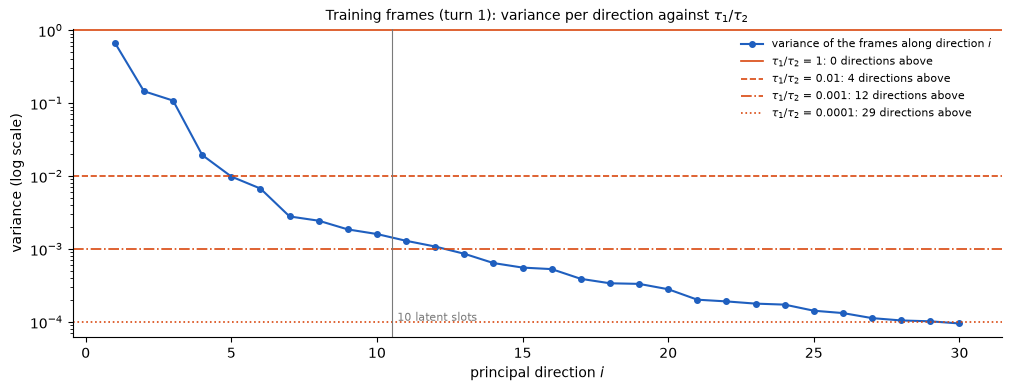

total variance of the frames: 0.9828   largest direction: 0.6746


In [8]:
sp = split(0)
TRAIN_EX = training_frames(PREDICTORS[(0, "val")], sp.inner_train, np.random.default_rng())
lam = eigenvalues(TRAIN_EX)
plot_eigenvalues(lam, [1.0, 1e-2, 1e-3, 1e-4], "Training frames (turn 1): variance per direction against $\\tau_1/\\tau_2$",
                 os.path.join(FIG_DIR, "diff_weights_eigenvalues.png"))
print(f"total variance of the frames: {lam.sum():.4f}   largest direction: {lam[0]:.4f}")

## 3. Validation results

Every setting, trained 5 times in each of the 5 turns and scored on the validation fold of its turn. The table gives,
per setting, the validation RMSE (mean ± standard deviation of its 25 runs), the mean number of active latent slots,
the mean KL in nats, and the error of always answering the mean frame on the same frames. The figure shows the same
numbers against the ratio $\tau_1/\tau_2$.

In [9]:
TAU1 = [1 / 3, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
TAU3 = [1 / 3, 0.1, 0.01]
GRID = [(t1, 1 - t1 - t3, t3) for t3 in TAU3 for t1 in TAU1]
REPEATS = 5

tasks = [(f, "val", tau, False, rep) for f in range(5) for tau in GRID for rep in range(REPEATS)]
VAL = run_all(tasks, "diff_weights_validation.csv")
VAL_SUM = summarise(VAL)
print(f"{len(GRID)} settings x 5 turns x {REPEATS} repeats = {len(VAL)} validation runs")
VAL_SUM.sort_values("rmse_mean").assign(
    tau_1=lambda d: d.tau_1.map(fmt), tau_2=lambda d: d.tau_2.map(fmt), tau_3=lambda d: d.tau_3.map(fmt),
    **{"validation RMSE": lambda d: [pm(m, s) for m, s in zip(d.rmse_mean, d.rmse_std)]}
)[["tau_1", "tau_2", "tau_3", "validation RMSE", "active", "kl", "mean_frame", "runs"]].round(
    {"active": 1, "kl": 1, "mean_frame": 4}).reset_index(drop=True)

450 runs saved to results/diff_weights_validation.csv
18 settings x 5 turns x 5 repeats = 450 validation runs


,tau_1,tau_2,tau_3,validation RMSE,active,kl,mean_frame,runs
0,1e-4,0.6666,1/3,0.0204 ± 0.0064,9.1,18.7,0.0478,25
1,1e-4,0.8999,0.1,0.0206 ± 0.0061,9.8,20.9,0.0478,25
2,1e-5,0.99,0.01,0.0213 ± 0.0074,10.0,32.2,0.0477,25
3,1e-5,0.9,0.1,0.0213 ± 0.0075,10.0,33.7,0.0477,25
4,1e-3,0.6657,1/3,0.0215 ± 0.0062,5.3,7.1,0.0478,25
5,1e-5,0.6667,1/3,0.0216 ± 0.0069,10.0,30.5,0.0477,25
6,1e-3,0.989,0.01,0.0217 ± 0.0066,6.6,8.7,0.0478,25
7,1e-3,0.899,0.1,0.0219 ± 0.0088,6.2,8.3,0.0477,25
8,1e-4,0.9899,0.01,0.0219 ± 0.0079,9.8,21.0,0.0478,25
9,0.01,0.98,0.01,0.0233 ± 0.0069,1.6,2.7,0.0477,25


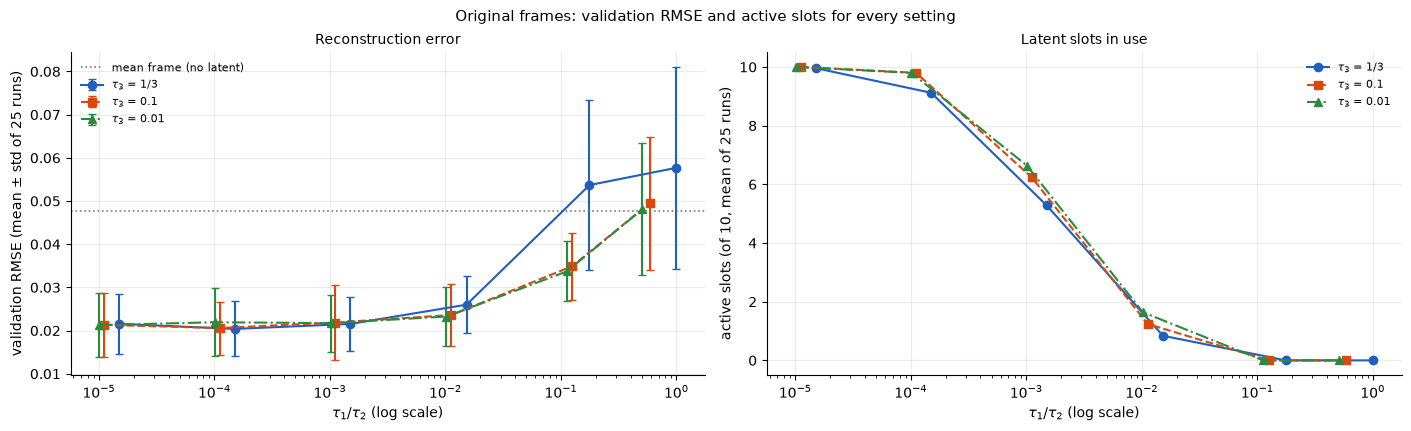

In [10]:
plot_validation(VAL_SUM, "Original frames: validation RMSE and active slots for every setting",
                os.path.join(FIG_DIR, "diff_weights_validation.png"))

## 4. Choosing the weights in each turn, and testing them

In each turn the setting with the lowest validation RMSE (averaged over its 5 repeats) is chosen. Only that setting is
trained on the 40 non-test viewers (5 more times) and scored on the test fold. The test folds play no part in the
choice. The table lists, per turn, the chosen weights, their validation RMSE and their test RMSE (mean ± standard
deviation of the 5 repeats), with the error of always answering the mean frame on the same test frames.

In [11]:
CHOICE = choose_per_fold(VAL)                    # in each turn: the lowest mean validation RMSE (decided by validation only)
tasks = [(int(r.fold) - 1, "test", (r.tau_1, r.tau_2, r.tau_3), False, rep)
         for r in CHOICE.itertuples() for rep in range(REPEATS)]
TEST = run_all(tasks, "diff_weights_test.csv")

per_fold = TEST.groupby("fold").agg(test_mean=("rmse", "mean"), test_std=("rmse", "std"), active=("active", "mean"),
                                    mean_frame=("mean_frame_rmse", "mean")).reset_index()
per_fold = CHOICE.rename(columns={"rmse": "validation RMSE"}).merge(per_fold, on="fold")
display_fold = per_fold.assign(**{c: per_fold[c].map(fmt) for c in ["tau_1", "tau_2", "tau_3"]},
                               **{"test RMSE": [pm(m, s) for m, s in zip(per_fold.test_mean, per_fold.test_std)]})
print(display_fold[["fold", "tau_1", "tau_2", "tau_3", "validation RMSE", "test RMSE", "active", "mean_frame"]]
      .round({"validation RMSE": 4, "active": 1, "mean_frame": 4}).to_string(index=False))
print(f"\nTEST RMSE over all 5 turns x {REPEATS} repeats: {pm(TEST.rmse.mean(), TEST.rmse.std())}   "
      f"(mean frame on the same frames: {TEST.mean_frame_rmse.mean():.4f};  active slots {TEST.active.mean():.1f} of 10)")

25 runs saved to results/diff_weights_test.csv
 fold tau_1  tau_2 tau_3  validation RMSE       test RMSE  active  mean_frame
    1  1e-5    0.9   0.1           0.0214 0.0299 ± 0.0043    10.0      0.0592
    2  1e-5    0.9   0.1           0.0198 0.0179 ± 0.0018    10.0      0.0533
    3  1e-5    0.9   0.1           0.0099 0.0210 ± 0.0013    10.0      0.0560
    4  1e-4 0.8999   0.1           0.0192 0.0129 ± 0.0016    10.0      0.0518
    5  1e-4 0.8999   0.1           0.0282 0.0244 ± 0.0042     9.8      0.0456

TEST RMSE over all 5 turns x 5 repeats: 0.0212 ± 0.0065   (mean frame on the same frames: 0.0532;  active slots 10.0 of 10)


## 5. One example run

One more training of the setting with the lowest mean validation RMSE, in turn 1 (on the 40 non-test viewers), to show
what it does: the 7 test frames of turn 1, their
reconstruction from one drawn $z_k$, and the spread $\sigma_{z,k}$ of each latent slot (blue = active, grey = collapsed).

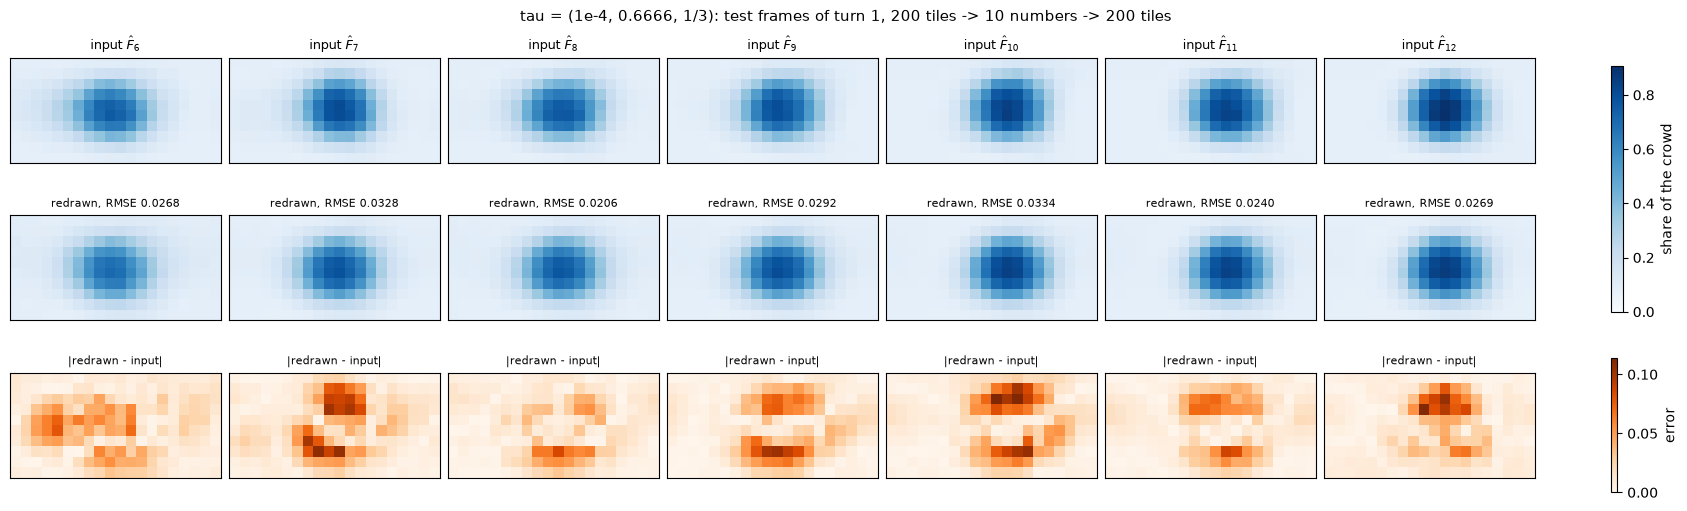

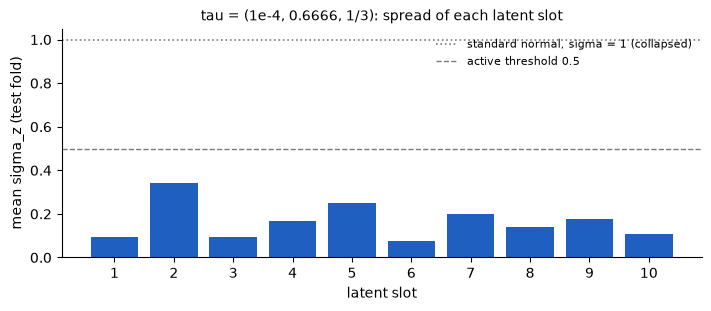

In [12]:
BEST = VAL_SUM.loc[VAL_SUM.rmse_mean.idxmin()]
best_tau = (BEST.tau_1, BEST.tau_2, BEST.tau_3)
A, R, sigma = example_run(0, best_tau, False)
name = f"tau = ({fmt(best_tau[0])}, {fmt(best_tau[1])}, {fmt(best_tau[2])})"
plot_reconstruction(A, R, f"{name}: test frames of turn 1, 200 tiles -> 10 numbers -> 200 tiles",
                    os.path.join(FIG_DIR, "diff_weights_example_reconstruction.png"))
plot_slots(sigma, f"{name}: spread of each latent slot", os.path.join(FIG_DIR, "diff_weights_example_slots.png"))

## 6. What the results show

The cell below summarises the validation runs per value of $\tau_1$ (the three values of $\tau_3$ together): the range
of the validation RMSE, the active slots and the KL. What to look for:

- whether the ratio $\tau_1/\tau_2$ **decides if the latent is used** (active slots rise as $\tau_1$ falls) and how
  much $\tau_3$ matters;
- **how far the best settings get below the mean frame**;
- **whether the chosen weights are the same in every turn**, and whether on the test folds they beat equal weights
  (`sport_vae_normalised_tiles.ipynb`, same folds) and the mean frame in every turn.

### Conclusion

The weights with the lowest validation RMSE on the original frames (the rule fixed before the runs), and their test
result, are printed below.

In [13]:
by_t1 = VAL_SUM.groupby("tau_1").agg(rmse_lo=("rmse_mean", "min"), rmse_hi=("rmse_mean", "max"),
                                     active_lo=("active", "min"), active_hi=("active", "max"),
                                     kl=("kl", "mean")).sort_index(ascending=False)
print(f"mean frame (no latent) on the validation frames: {VAL_SUM.mean_frame.mean():.4f}\n")
print("per tau_1 (tau_3 = 1/3, 0.1, 0.01 together):")
print(by_t1.rename(index=fmt).round({"rmse_lo": 4, "rmse_hi": 4, "active_lo": 1, "active_hi": 1, "kl": 1}).to_string())

BEST = VAL_SUM.loc[VAL_SUM.rmse_mean.idxmin()]
print(f"\nlowest validation RMSE: tau_1 = {fmt(BEST.tau_1)}, tau_2 = {fmt(BEST.tau_2)}, tau_3 = {fmt(BEST.tau_3)}, "
      f"validation RMSE {pm(BEST.rmse_mean, BEST.rmse_std)}, {BEST.active:.1f} active slots")
print("chosen per turn: " + ", ".join(f"turn {int(r.fold)}: tau_1 = {fmt(r.tau_1)}" for r in CHOICE.itertuples()))
print(f"test RMSE of weights chosen per turn: {pm(TEST.rmse.mean(), TEST.rmse.std())}  "
      f"(mean frame {TEST.mean_frame_rmse.mean():.4f}, {TEST.active.mean():.1f} active slots)")

EQ_FILE = os.path.join(RES_DIR, "normalised_tiles_test.csv")
if os.path.exists(EQ_FILE):
    EQ = pd.read_csv(EQ_FILE)
    EQ = EQ[~EQ.normalised]
    d = EQ.groupby("fold").rmse.mean() - TEST.groupby("fold").rmse.mean()
    below_mf = (TEST.groupby("fold").rmse.mean() < TEST.groupby("fold").mean_frame_rmse.mean()).sum()
    print(f"equal weights on the same test folds: {pm(EQ.rmse.mean(), EQ.rmse.std())}")
    print(f"chosen weights beat equal weights in {(d > 0).sum()} of 5 turns (difference {d.min():+.4f} to {d.max():+.4f}); "
          f"below the mean frame in {below_mf} of 5 turns")
else:
    print(f"({EQ_FILE} not found: run sport_vae_normalised_tiles.ipynb for the equal-weights comparison)")

mean frame (no latent) on the validation frames: 0.0478

per tau_1 (tau_3 = 1/3, 0.1, 0.01 together):
       rmse_lo  rmse_hi  active_lo  active_hi    kl
tau_1                                              
1/3     0.0481   0.0577        0.0        0.0   0.0
0.1     0.0337   0.0537        0.0        0.0   0.3
0.01    0.0233   0.0260        0.8        1.6   2.4
1e-3    0.0215   0.0219        5.3        6.6   8.1
1e-4    0.0204   0.0219        9.1        9.8  20.2
1e-5    0.0213   0.0216       10.0       10.0  32.1

lowest validation RMSE: tau_1 = 1e-4, tau_2 = 0.6666, tau_3 = 1/3, validation RMSE 0.0204 ± 0.0064, 9.1 active slots
chosen per turn: turn 1: tau_1 = 1e-5, turn 2: tau_1 = 1e-5, turn 3: tau_1 = 1e-5, turn 4: tau_1 = 1e-4, turn 5: tau_1 = 1e-4
test RMSE of weights chosen per turn: 0.0212 ± 0.0065  (mean frame 0.0532, 10.0 active slots)
equal weights on the same test folds: 0.0623 ± 0.0187
chosen weights beat equal weights in 5 of 5 turns (difference +0.0309 to +0.0548); below t